# Session Inspection Notebook
This notebook loads the `sessions_dirty.pkl` file and performs basic integrity checks.

In [1]:
import sys
import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Add project root to sys.path
project_root = "/home/fsp585/Desktop/FiberphotometryCode"
if project_root not in sys.path:
    sys.path.append(project_root)

pkl_path = "/home/fsp585/Desktop/FiberphotometryCode/monoamine_interactions/data/sessions_jonathan_juvenile_intruder_dirty.pkl"


## Load Sessions

In [2]:
with open(pkl_path, "rb") as f:
    sessions = pickle.load(f)

print(f"Loaded {len(sessions)} sessions.")


Loaded 12 sessions.


## Session Summary Table

In [3]:
rows = []
for s in sessions:
    md = s.metadata
    rows.append({
        "session_id": s.session_id,
        "animal_id": md.get("animal_id"),
        "genotype": md.get("genotype"),
        "chamber": md.get("chamber"),
        "has_photometry": "470" in getattr(s, 'photometry', {}),
        "n_signals": len(md.get("signal_meta", {}))
    })

df_summary = pd.DataFrame(rows)
df_summary


,session_id,animal_id,genotype,chamber,has_photometry,n_signals
0,2026-01-14T09_45_33_bottom_left,84,TH-Cre,bottom_left,True,2
1,2026-01-14T10_44_31_bottom_left,85,TH-Cre,bottom_left,True,2
2,2026-01-14T11_37_02_bottom_left,86,TH-Cre,bottom_left,True,2
3,2026-01-14T12_33_27_bottom_left,2,WT,bottom_left,True,2
4,2026-01-14T13_12_43_bottom_left,6,WT,bottom_left,True,2
5,2026-01-14T13_53_32_bottom_left,10,WT,bottom_left,True,2
6,2026-01-14T14_33_58_bottom_left,4,WT,bottom_left,False,0
7,2026-01-14T15_15_19_bottom_left,8,WT,bottom_left,False,0
8,2026-01-14T15_58_04_bottom_left,1,WT,bottom_left,True,2
9,2026-01-14T16_39_31_bottom_left,3,WT,bottom_left,True,2


In [8]:
s.metadata

{'timestamp': '2026-01-15T11_03_48',
 'chamber': 'bottom_left',
 'camsets_present': ['Arena1234_CenterTopCamVid', 'Arena1and2_LeftTopCamVid'],
 'cam_slots_present': ['Arena1234_CenterTopCamVid',
  'Arena1and2_LeftTopCamVid'],
 'arenas_present': ['Arena1234', 'Arena1and2'],
 'chamber_index': 1,
 'original_video_path': '/home/fsp585/Desktop/FiberphotometryCode/src_mono_inter/jonathan_juvenile_intruder/video_files/T12_e.5.e.e_Arena1and2_LeftTopCamVid_2026-01-15T11_03_48_lower.avi',
 'trial_id': 'T12_e.5.e.e',
 'animal_id': '5',
 'n_chambers': 4,
 'photometry_ts_csv': '2026-01-15T11:03:48',
 'photometry_csv_path': '/home/fsp585/Desktop/FiberphotometryCode/src_mono_inter/jonathan_juvenile_intruder/csvs/T12_e.5.e.e/photometry_data_combined_2026-01-15T11.03.48.csv',
 'photometry_source': 'csv_combined',
 'injection': 'saline',
 'cohort': 'Juvenile_intruder_baseline',
 'exclude': False,
 'inarena_min': 7.6,
 'home_cage_min': 23.4,
 'juvenile_first_sniff_min': 25.637,
 'juvenile_removed_min': 2

## Deep Dive: First Valid Session

In [4]:
# Find first session with signals
s = next((sess for sess in sessions if sess.metadata.get("signal_meta")), None)

if s:
    print(f"Inspecting Session: {s.session_id}")
    print(f"Animal ID: {s.metadata.get('animal_id')}")
    print(f"Signal Meta: {s.metadata.get('signal_meta')}")
    
    if hasattr(s, 'photometry'):
        if '470' in s.photometry:
            print("\n470 Stream Columns:", s.photometry['470'].columns.tolist())
            print("470 Stream Shape:", s.photometry['470'].shape)
            display(s.photometry['470'].head())
        
        if '415' in s.photometry:
            print("\n415 Stream Shape:", s.photometry['415'].shape)
else:
    print("No sessions with signals found.")


Inspecting Session: 2026-01-14T09_45_33_bottom_left
Animal ID: 84
Signal Meta: {'signal_0': {'orig_fiber': 'G4', 'orig_letter': 'G', 'fiber_num': '4', 'region': 'lNAc_DA', 'brain_reg': 'lNAc_DA', 'hemisphere': 'Left'}, 'signal_1': {'orig_fiber': 'G6', 'orig_letter': 'G', 'fiber_num': '6', 'region': 'rNAc_5HT', 'brain_reg': 'rNAc_5HT', 'hemisphere': 'Right'}}

470 Stream Columns: ['FrameCounter', 'SystemTimestamp', 'LedState', 'ComputerTimestamp', 'signal_0', 'signal_1', 'frame_idx', 'signal_0_zscore_ransac', 'signal_0_zscore_wallace', 'signal_0_dff', 'signal_0_zscore', 'signal_0_prominence', 'signal_1_zscore_ransac', 'signal_1_zscore_wallace', 'signal_1_dff', 'signal_1_zscore', 'signal_1_prominence']
470 Stream Shape: (51587, 17)


,FrameCounter,SystemTimestamp,LedState,ComputerTimestamp,signal_0,signal_1,frame_idx,signal_0_zscore_ransac,signal_0_zscore_wallace,signal_0_dff,signal_0_zscore,signal_0_prominence,signal_1_zscore_ransac,signal_1_zscore_wallace,signal_1_dff,signal_1_zscore,signal_1_prominence
0,874,280.124768,2,3.514524e+07,0.003935,0.003941,0,0.954295,0.954295,0.003418,2.590739,1.930403,-0.752569,-0.752569,0.004839,2.004388,0.582092
1,879,280.187296,2,3.514530e+07,0.003930,0.003943,0,-0.630024,-0.630024,0.002197,2.570791,0.314302,-0.195495,-0.195495,0.00553,2.008529,1.120484
2,884,280.249824,2,3.514536e+07,0.003931,0.003943,0,-0.036447,-0.036447,0.002441,2.57478,1.193919,-0.199452,-0.199452,0.00553,2.008529,1.115579
3,889,280.312416,2,3.514543e+07,0.003936,0.003941,0,1.489259,1.489259,0.003662,2.594728,2.687842,-0.591213,-0.591213,0.005069,2.005768,0.72287
4,894,280.374880,2,3.514549e+07,0.003931,0.003947,0,-0.007194,-0.007194,0.002441,2.57478,1.26593,0.572793,0.572793,0.006452,2.01405,1.88593



415 Stream Shape: (51586, 7)


## Quick Plot

lNAc_DA, rNAc_5HT



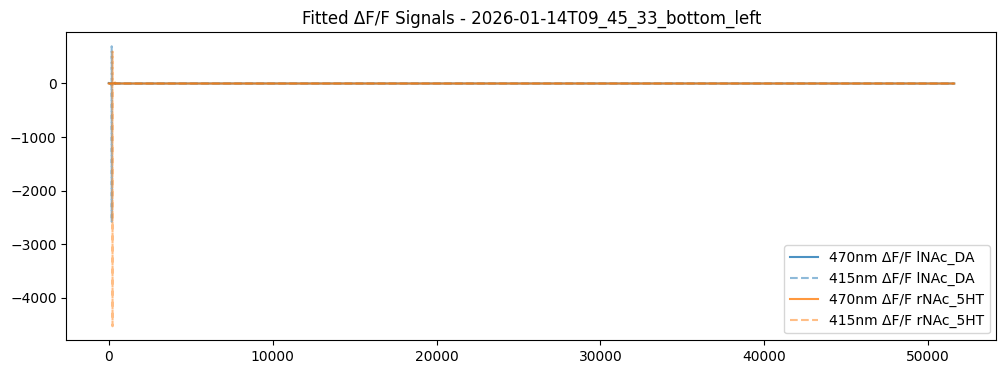

lNAc_DA, rNAc_5HT



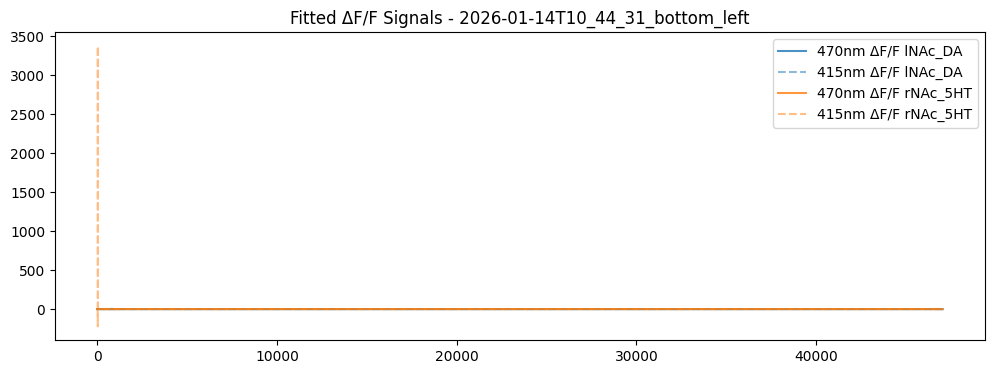

lNAc_5HT, rNAc_DA



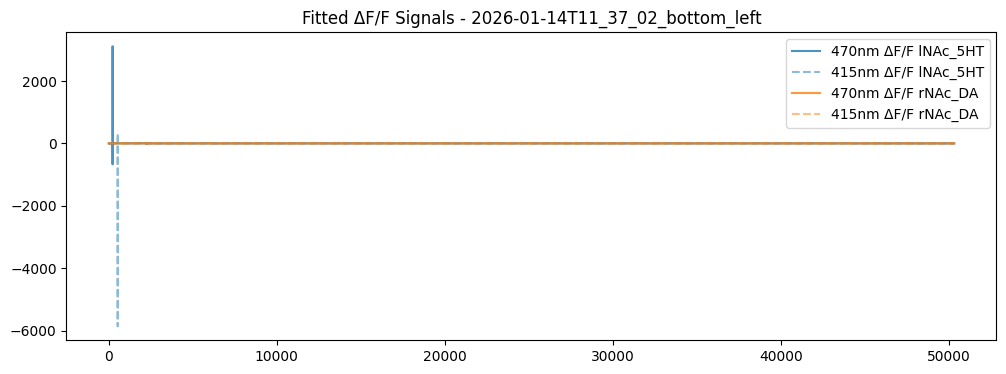

VTA_NE, NAc_DA



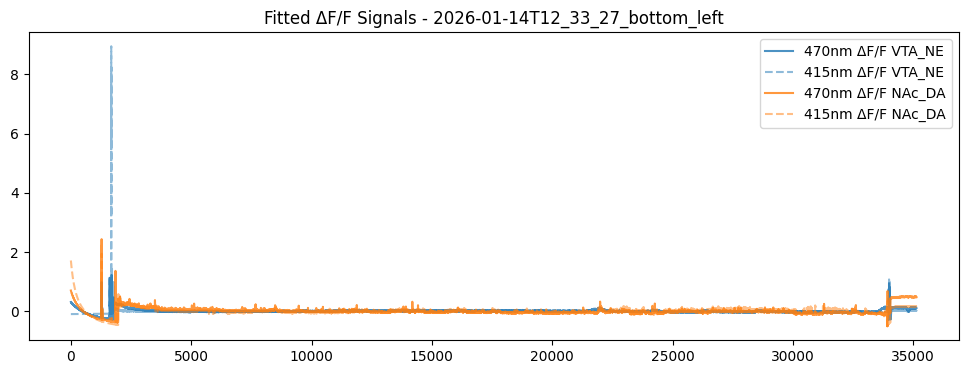

DRN_NE, NAc_5HT



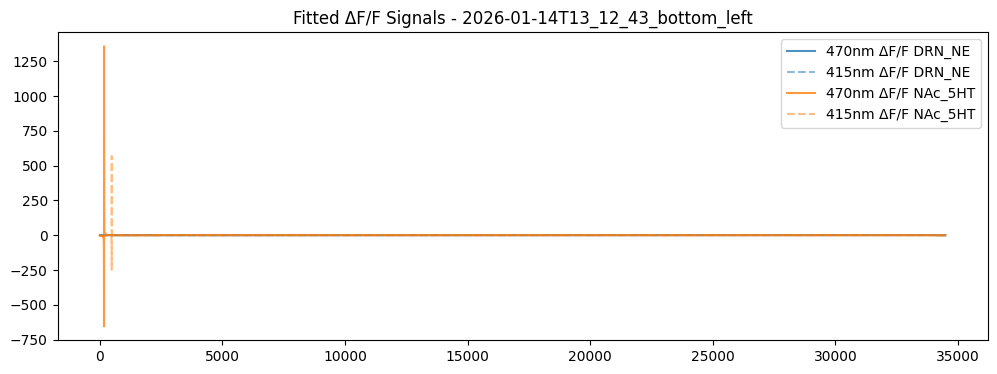

DRN_NE, NAc_5HT



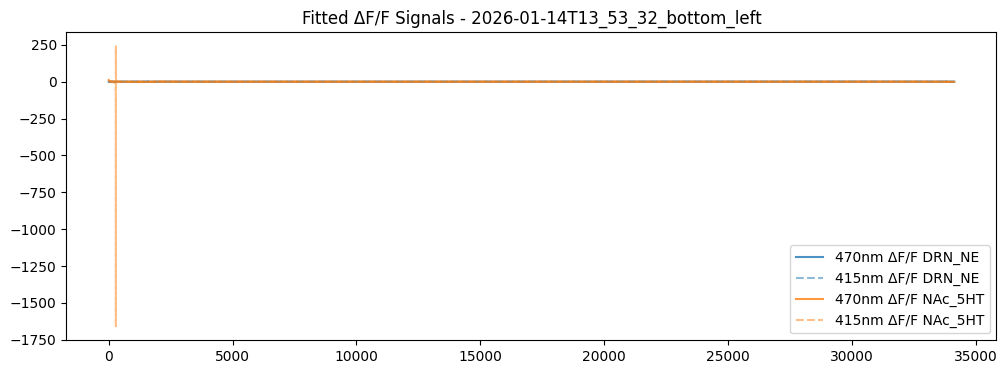

DRN_NE, NAc_5HT



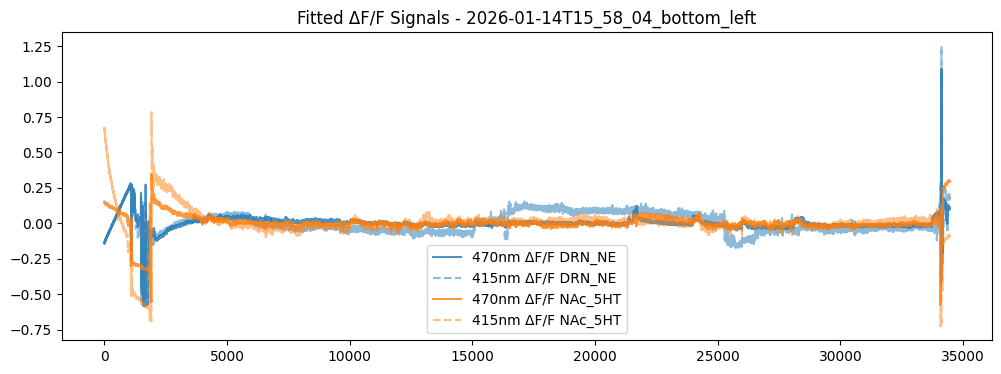

DRN_NE, NAc_5HT



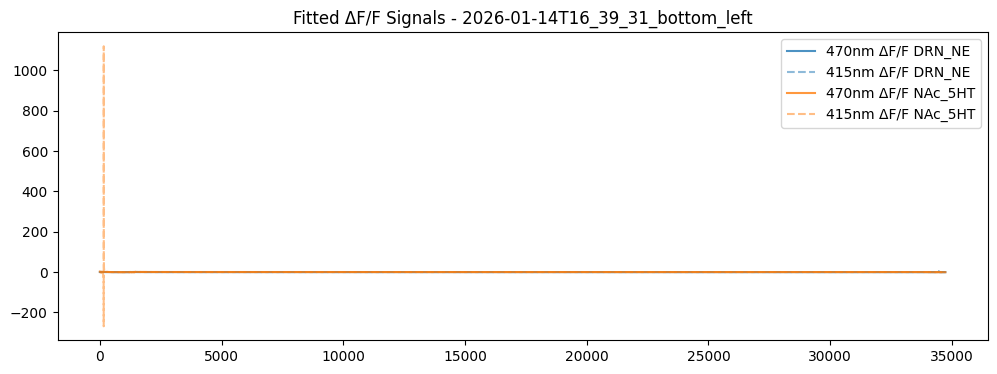

lNAc_5HT, rNAc_DA



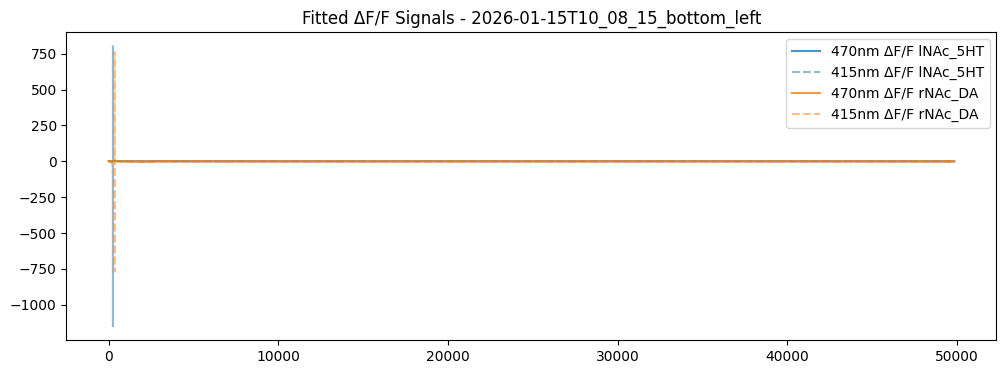

VTA_NE, NAc_DA



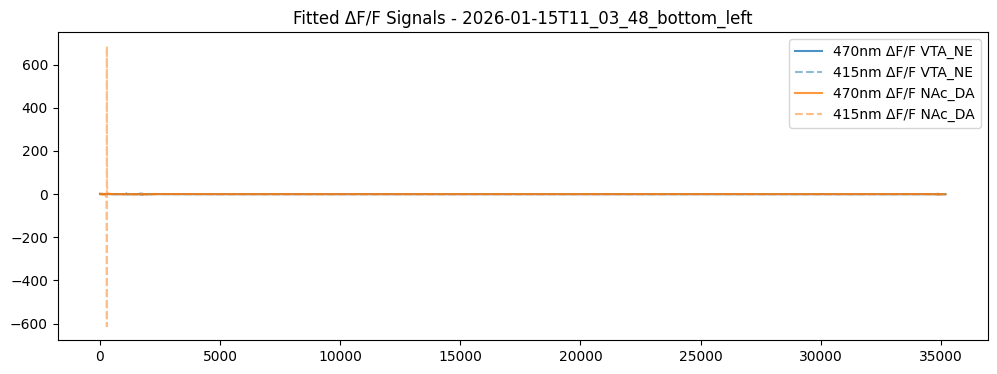

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from utils.photometry import fit_biexponential_dff
        
for s in sessions:
    if s and hasattr(s, 'photometry') and '470' in s.photometry:
        fig, ax = plt.subplots(figsize=(12, 4))
        cols = [c for c in s.photometry['470'].columns if 'signal' in c and 'zscore' not in c and 'dff' not in c]
        
        for ixc, c in enumerate(cols[:2]):
            region_label = s.metadata.get(c, c) 
            
            sig_470 = s.photometry['470'][c].values
            dff_470 = fit_biexponential_dff(sig_470)
            p = ax.plot(dff_470, label=f"470nm \u0394F/F {region_label}", alpha=0.8)
            
            if '415' in s.photometry and c in s.photometry['415'].columns:
                sig_415 = s.photometry['415'][c].values
                dff_415 = fit_biexponential_dff(sig_415)
                ax.plot(dff_415, label=f"415nm \u0394F/F {region_label}", alpha=0.5, linestyle='--', color=p[0].get_color())
                
            if ixc == 0:
                print(region_label, end=', ')
            else:
                print(region_label, end='\n\n')
                
        ax.set_title(f"Fitted \u0394F/F Signals - {s.session_id}")
        ax.legend()
        plt.show()